# Gear dynamics 04: backlash, impacts and rattle

Every real gear pair has clearance between the non-working flanks, the **backlash**. It is
needed for thermal expansion, centre-distance tolerance and the oil film. In notebooks 02
and 03 the mesh spring was allowed to *pull*. That is only correct with zero backlash, where
the coast flank takes over immediately. Now the two flanks become two separate **unilateral**
contacts with a gap in between:

$$\delta = r_{b1}\theta_1 - r_{b2}\theta_2,\qquad
  F_d = \max\!\big(0,\;k(\delta - \tfrac{j_n}{2}) + c\dot\delta\big)\ \text{if}\ \delta > \tfrac{j_n}{2},\qquad
  F_r = \max\!\big(0,\;k(-\delta - \tfrac{j_n}{2}) - c\dot\delta\big)\ \text{if}\ \delta < -\tfrac{j_n}{2}$$

and the mesh force is $F = F_d - F_r$. The `max(0, ·)` stops the damper from making the
contact "sticky" during separation.

**Experiments:** **A** your preload-and-release with gear 2 clamped · **B** the same with
both gears free · **C** idle rattle from crankshaft speed irregularity · **D** the jump
phenomenon in a speed sweep.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import geardyn as gd

gd.style()
jn = 60e-6                       # total normal backlash along the LOA
gp = gd.GearPair(backlash=jn)
g_half = jn / 2
T1 = 40.0
F0 = T1 / gp.rb1
print(gp.summary())

z1 / z2                                 24 / 48  -
ratio i = z2/z1                           2.000  -
module                                     2.50  mm
pressure angle                             20.0  deg
pitch radii r1 / r2               30.00 / 60.00  mm
base radii rb1 / rb2              28.19 / 56.38  mm
centre distance a                         90.00  mm
base pitch pb                             7.380  mm
contact ratio eps_alpha                   1.675  -
J1 / J2                   1.498e-04 / 2.397e-03  kg m^2
m1 / m2                           0.333 / 1.332  kg
equivalent mass m_eq                     0.1508  kg
mesh stiffness k (mean)                   316.3  N/um
mesh damping c                            690.6  N s/m
mesh natural frequency                     7288  Hz
backlash j_n                                 60  um


## 1  How much backlash, and in which units?

Backlash is specified in several equivalent ways. Here it is the **normal** backlash $j_n$,
measured along the LOA, because that is where the dynamics live. Conversions:

* circumferential backlash on the pitch circle: $j_t = j_n/\cos\alpha$;
* angular free play of gear 1 with gear 2 held: $\Delta\theta_1 = j_n / r_{b1}$;
* a centre-distance increase $\Delta a$ opens it by $\Delta j_n = 2\,\Delta a\sin\alpha$.
  This is why lateral bearing motion matters (notebook 05).

j_n = 60 um  ->  j_t = 63.9 um, free play of gear 1 = 7.3 arcmin
compare: static mesh deflection at 40 N m = 4.5 um  (the gap is 13x larger)
centre distance +50 um opens backlash by 34.2 um


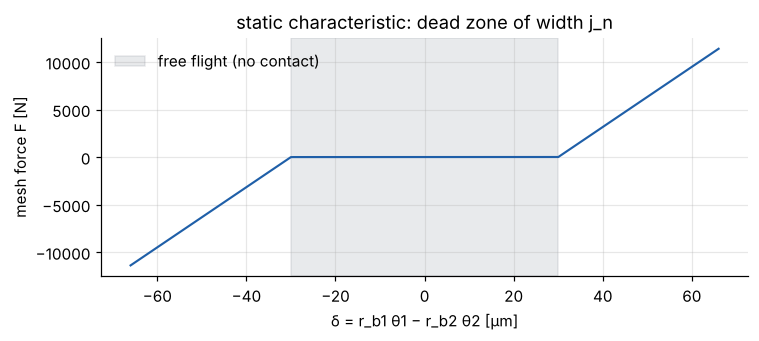

In [2]:
print(f"j_n = {jn*1e6:.0f} um  ->  j_t = {jn/np.cos(gp.alpha)*1e6:.1f} um, "
      f"free play of gear 1 = {np.degrees(jn/gp.rb1)*60:.1f} arcmin")
print(f"compare: static mesh deflection at 40 N m = {F0/gp.k_mesh*1e6:.1f} um  (the gap is {jn/(F0/gp.k_mesh):.0f}x larger)")
print(f"centre distance +50 um opens backlash by {2*50e-6*np.sin(gp.alpha)*1e6:.1f} um")

d = np.linspace(-2.2 * g_half, 2.2 * g_half, 500)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(d * 1e6, (gd.flank_force(d - g_half, 0, gp.k_mesh, 0) - gd.flank_force(-d - g_half, 0, gp.k_mesh, 0)))
ax.axvspan(-g_half * 1e6, g_half * 1e6, color=gd.C["grey"], alpha=0.15, label="free flight (no contact)")
ax.set_xlabel("δ = r_b1 θ1 − r_b2 θ2 [µm]"); ax.set_ylabel("mesh force F [N]")
ax.set_title("static characteristic: dead zone of width j_n"); ax.legend()
plt.tight_layout()

## 2  Experiment A: clamp gear 2, preload gear 1, release

Same as notebook 02, now with 60 µm backlash. Gear 1 is twisted against the drive flank by
40 N m (4.5 µm of tooth deflection) and released at $t = 0$:

1. the tooth spring pushes gear 1 back, and the strain energy $V_0 = F_0^2/2k$ becomes kinetic energy;
2. gear 1 **flies** across the 60 µm gap at constant speed $v = \sqrt{2V_0/m_1'}$ with $m_1' = J_1/r_{b1}^2$;
3. it **impacts the coast flank**, and the contact damper takes a share of the energy;
4. it bounces back, crosses the gap again, hits the drive flank, and so on.

Without damping, energy conservation gives a neat result: the impact force on the coast
flank equals the preload force $F_0$. Nothing is gained by "running up" across the gap,
because the energy is fixed by the preload.

flight speed after release: undamped 0.184 m/s, simulated 0.172 m/s (the damper already takes some energy during the push-off)
first gap crossing takes 0.327 ms; the clamped-pair period without backlash was 0.153 ms
energy balance error: 1.7e-06 V0


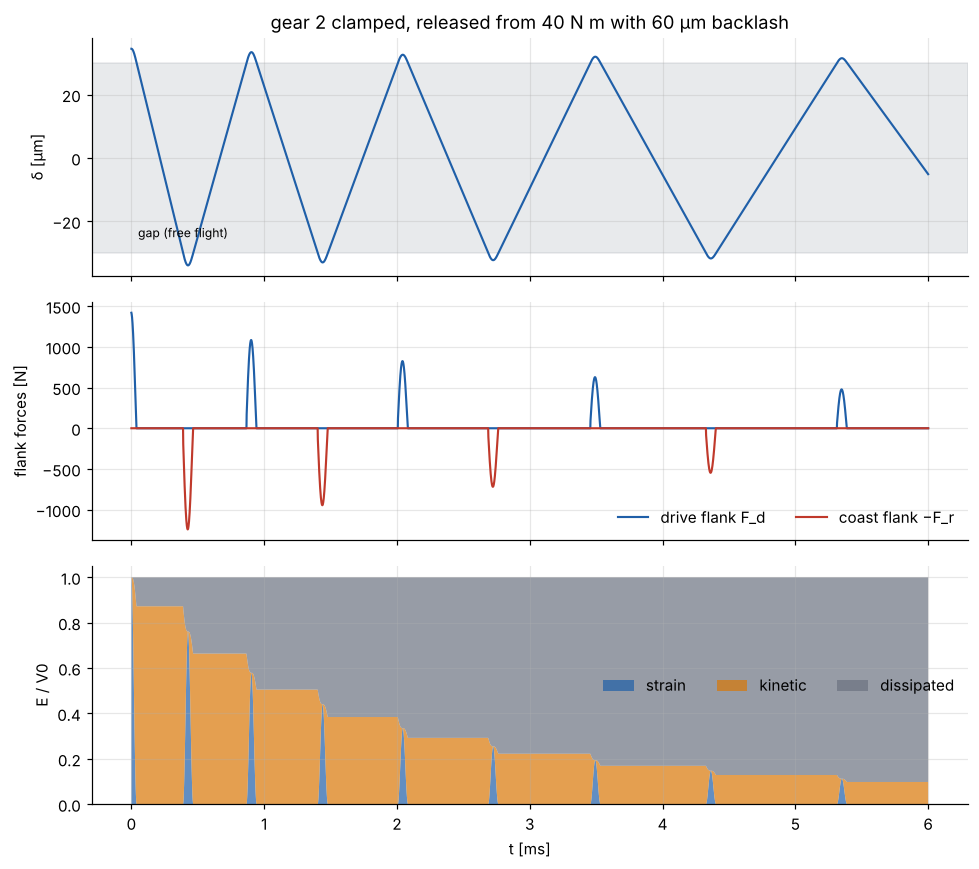

In [3]:
mA = gd.torsional_pair(gp, contact="backlash")
mA.fix("th2")
Q = np.zeros(2); Q[0] = T1
q0 = mA.static(Q)
rA = mA.simulate(6e-3, q0=q0, n_out=12000)
mesh = rA.mesh[0]
dA = gp.rb1 * rA["th1"]
v_fly = np.sqrt(2 * (F0**2 / 2 / gp.k_mesh) / (gp.J1 / gp.rb1**2))

fig, ax = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
tm = rA.t * 1e3
ax[0].plot(tm, dA * 1e6, color=gd.C["blue"])
ax[0].axhspan(-g_half * 1e6, g_half * 1e6, color=gd.C["grey"], alpha=0.15)
ax[0].set_ylabel("δ [µm]"); ax[0].set_title("gear 2 clamped, released from 40 N m with 60 µm backlash")
ax[0].text(0.05, -25, "gap (free flight)", fontsize=8)
ax[1].plot(tm, mesh["Fd"], label="drive flank F_d")
ax[1].plot(tm, -mesh["Fr"], label="coast flank −F_r")
ax[1].set_ylabel("flank forces [N]"); ax[1].legend(ncol=2, loc="lower right")
V0 = rA.V[0]
ax[2].stackplot(tm, rA.V / V0, rA.T / V0, rA.E_diss / V0, labels=["strain", "kinetic", "dissipated"],
                colors=[gd.C["blue"], gd.C["orange"], gd.C["grey"]], alpha=0.7)
ax[2].set_ylabel("E / V0"); ax[2].set_xlabel("t [ms]"); ax[2].legend(ncol=3, loc="center right")
plt.tight_layout()
print(f"flight speed after release: undamped {v_fly:.3f} m/s, simulated {np.max(np.abs(gp.rb1*rA.vel('th1'))):.3f} m/s "
      f"(the damper already takes some energy during the push-off)")
print(f"first gap crossing takes {jn/v_fly*1e3:.3f} ms; the clamped-pair period without backlash was {1e3/6519:.3f} ms")
print(f"energy balance error: {np.max(np.abs(rA.energy_residual))/V0:.1e} V0")

### Phase portrait and coefficient of restitution

For each contact episode, compare the approach speed with the separation speed. For a
linear spring-damper contact the coefficient of restitution is
$e = \exp(-\pi\zeta'/\sqrt{1-\zeta'^2})$, with $\zeta' = c/(2\sqrt{k m_1'})$ the damping ratio of
*this* contact (gear 1 against a clamped gear 2). The `max(0, ·)` clamp makes the
contact end slightly earlier, so the measured $e$ comes out a touch higher.

first coast-flank impact peak: 1243 N  (preload force F0 = 1419 N)


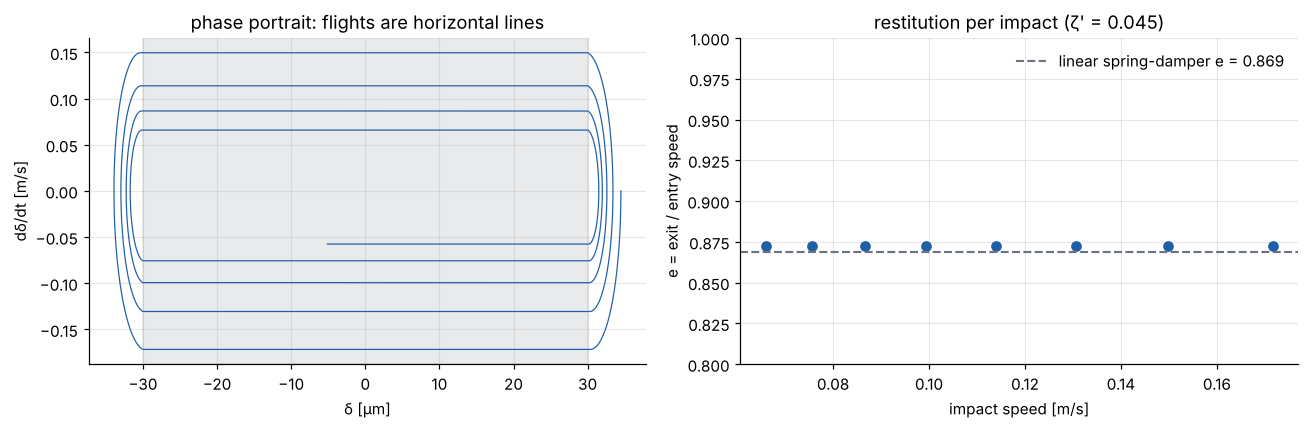

In [4]:
def episodes(pen, rate):
    """(entry speed, exit speed) for every contact episode of one flank"""
    on = (pen > 0).astype(int)
    starts = np.flatnonzero(np.diff(on) == 1)       # last sample before contact
    ends = np.flatnonzero(np.diff(on) == -1)        # last sample in contact
    out = []
    for a in starts:
        b = ends[ends > a]
        if len(b):
            out.append((rate[a], rate[b[0] + 1]))
    return np.array(out).reshape(-1, 2)


s_, pd, pr, pdd, prd = mA.meshes[0].kinematics(rA.q, rA.v)
ep = np.vstack([episodes(pd, pdd), episodes(pr, prd)])
e_meas = np.abs(ep[:, 1] / ep[:, 0])
zp = gp.c_mesh / (2 * np.sqrt(gp.k_mesh * gp.J1 / gp.rb1**2))
e_lin = np.exp(-np.pi * zp / np.sqrt(1 - zp**2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(dA * 1e6, gp.rb1 * rA.vel("th1"), lw=0.8)
ax[0].axvspan(-g_half * 1e6, g_half * 1e6, color=gd.C["grey"], alpha=0.15)
ax[0].set_xlabel("δ [µm]"); ax[0].set_ylabel("dδ/dt [m/s]"); ax[0].set_title("phase portrait: flights are horizontal lines")
ax[1].plot(np.abs(ep[:, 0]), e_meas, "o")
ax[1].axhline(e_lin, color=gd.C["grey"], ls="--", label=f"linear spring-damper e = {e_lin:.3f}")
ax[1].set_xlabel("impact speed [m/s]"); ax[1].set_ylabel("e = exit / entry speed")
ax[1].set_ylim(0.8, 1.0); ax[1].legend(); ax[1].set_title(f"restitution per impact (ζ' = {zp:.3f})")
plt.tight_layout()
print(f"first coast-flank impact peak: {mesh['Fr'].max():.0f} N  (preload force F0 = {F0:.0f} N)")

The energy now leaves in discrete steps, one per impact. Between impacts nothing is
dissipated. The oscillation is much slower than the 6.5 kHz of notebook 02 because the
period is dominated by flight time. That makes the frequency **amplitude-dependent**,
a hallmark of nonlinear systems. The smaller the bounce, the slower the flight and the lower
the frequency, until gear 1 comes to rest somewhere inside the gap.

Try `preload` = 10 N m and 80 N m: the impact force scales with $F_0$, the flight time
with $1/F_0$.

## 3  Experiment B: both gears free

Release the twisted pair without any clamp. The momentum along the LOA (notebook 02) is still
conserved, and it is zero, so the gears rattle against each other around a common
"centre". Each impact dissipates energy, and the pair ends up **separated** inside the
gap with zero relative speed, a state the bilateral spring of notebook 02 could never reach.

LOA momentum stays 0.0e+00; energy left after 8 ms: 4.1 %


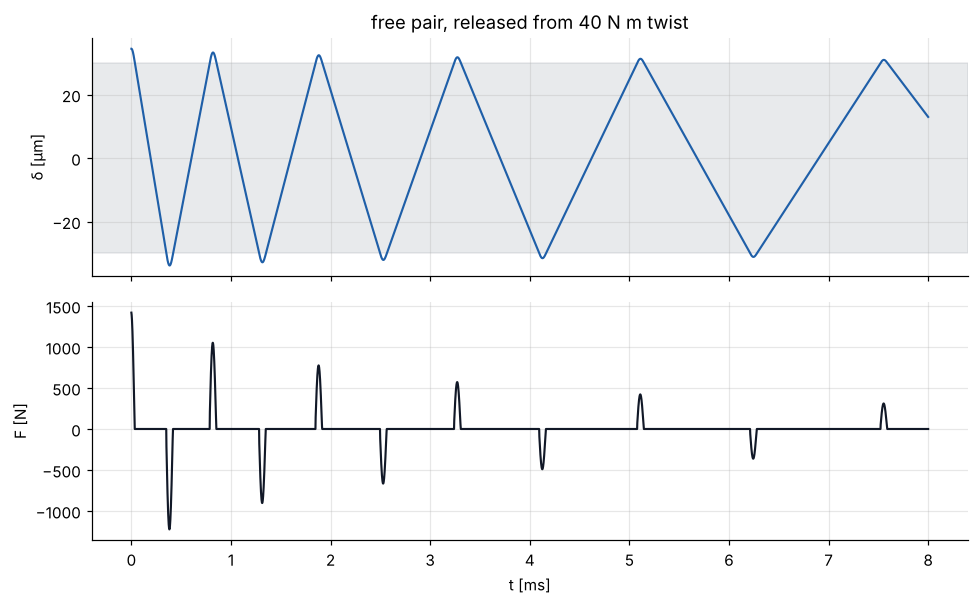

In [5]:
mB = gd.torsional_pair(gp, contact="backlash")
q0B = [(g_half + F0 / gp.k_mesh) / gp.rb1, 0.0]
rB = mB.simulate(8e-3, q0=q0B, n_out=12000)
dB = gp.rb1 * rB["th1"] - gp.rb2 * rB["th2"]
p = gp.J1 * rB.vel("th1") / gp.rb1 + gp.J2 * rB.vel("th2") / gp.rb2
fig, ax = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True)
ax[0].plot(rB.t * 1e3, dB * 1e6); ax[0].axhspan(-g_half * 1e6, g_half * 1e6, color=gd.C["grey"], alpha=0.15)
ax[0].set_ylabel("δ [µm]"); ax[0].set_title("free pair, released from 40 N m twist")
ax[1].plot(rB.t * 1e3, rB.mesh[0]["F"], color=gd.C["black"]); ax[1].set_ylabel("F [N]"); ax[1].set_xlabel("t [ms]")
plt.tight_layout()
print(f"LOA momentum stays {np.abs(p).max():.1e}; energy left after 8 ms: {(rB.T[-1]+rB.V[-1])/rB.V[0]*100:.1f} %")

## 4  Experiment C: idle rattle from speed irregularity

The classic gearbox noise problem: an engine at idle has a strong **2nd-order** speed
irregularity (four-stroke twin or four), which the input gear passes to an *unloaded*
gear, a loose gear or the gear driving the balancer or the oil pump. The loaded flank changes
when gear 2 can no longer follow the acceleration of gear 1.

Model: gear 1 is **kinematically prescribed** (the crankshaft is far heavier):
$\theta_1 = \Omega t + A\sin(\omega_e t)$ with $\Omega$ = 1500 rpm and $\omega_e = 2\Omega$.
Gear 2 has its own inertia and a small drag torque $T_d$ (oil churning, bearing friction).
For gear 2 to follow rigidly, the mesh must deliver
$J_2\ddot\theta_2 + T_d = J_2\tfrac{A}{i}\omega_e^2\sin(\cdot) + T_d$, and a tooth can only push.
Hence the **rattle threshold**

$$A_\text{crit} = \frac{i\,T_d}{J_2\,\omega_e^2}$$

Above it, gear 2 lifts off the drive flank once per excitation cycle, crosses the gap and
hits the coast flank.

A_crit = 0.097 deg of crank angle (order-2 amplitude), i.e. speed fluctuation +-5.1 rpm


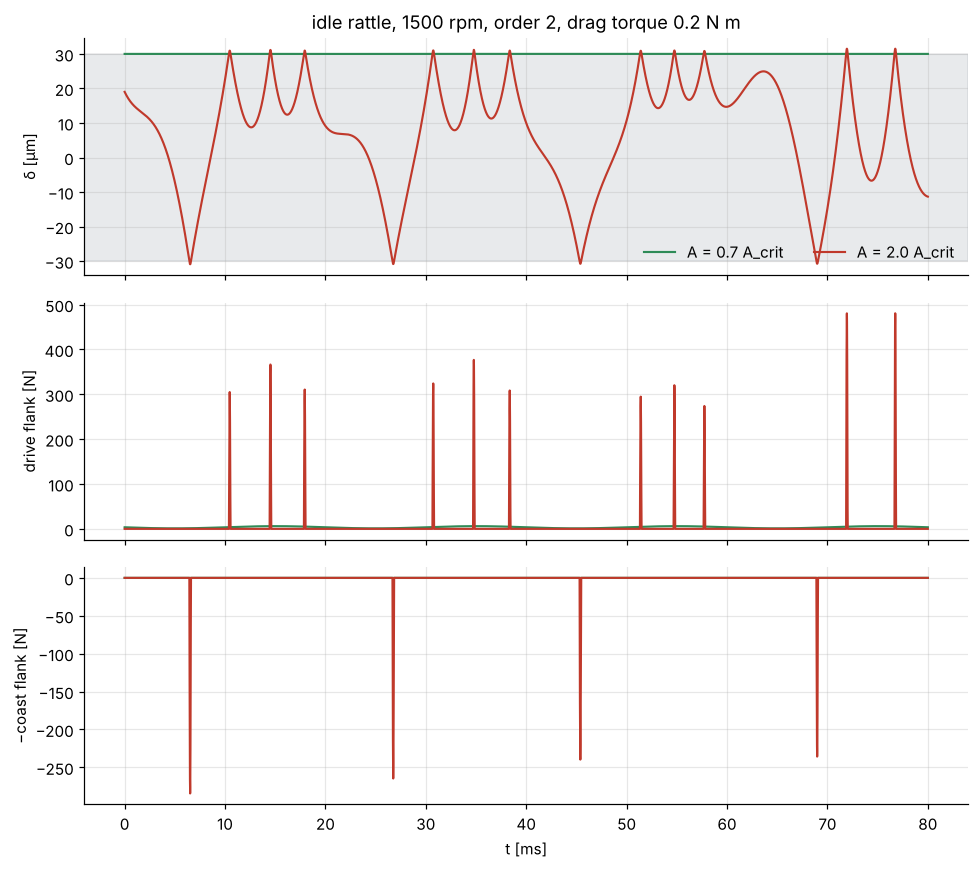

In [6]:
W = 1500 * 2 * np.pi / 60; we = 2 * W; Td = 0.2
A_crit = gp.i * Td / (gp.J2 * we**2)
print(f"A_crit = {np.degrees(A_crit):.3f} deg of crank angle (order-2 amplitude), "
      f"i.e. speed fluctuation +-{A_crit*we*60/2/np.pi:.1f} rpm")


def rattle(A, t_end=0.12, n_out=24000):
    m = gd.torsional_pair(gp.with_(), contact="backlash", stiffness="const")
    m.prescribe("th1", lambda t: W * t + A * np.sin(we * t), lambda t: W + A * we * np.cos(we * t),
                lambda t: -A * we**2 * np.sin(we * t))
    m.add_load("th2", lambda t, q, v: -Td)
    d0 = g_half + Td / gp.rb2 / gp.k_mesh
    r = m.simulate(t_end, q0=[0, -d0 / gp.rb2], v0=[W + A * we, (W + A * we) / gp.i], n_out=n_out)
    return r


fig, ax = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for A, col in [(0.7 * A_crit, gd.C["green"]), (2.0 * A_crit, gd.C["red"])]:
    r = rattle(A)
    dlt = gp.rb1 * r["th1"] - gp.rb2 * r["th2"]
    sel = r.t > 0.04
    tt = (r.t[sel] - 0.04) * 1e3
    ax[0].plot(tt, dlt[sel] * 1e6, color=col, label=f"A = {A/A_crit:.1f} A_crit")
    ax[1].plot(tt, r.mesh[0]["Fd"][sel], color=col)
    ax[2].plot(tt, -r.mesh[0]["Fr"][sel], color=col)
ax[0].axhspan(-g_half * 1e6, g_half * 1e6, color=gd.C["grey"], alpha=0.15)
ax[0].set_ylabel("δ [µm]"); ax[0].legend(ncol=2)
ax[1].set_ylabel("drive flank [N]"); ax[2].set_ylabel("−coast flank [N]"); ax[2].set_xlabel("t [ms]")
ax[0].set_title(f"idle rattle, 1500 rpm, order 2, drag torque {Td} N m")
plt.tight_layout()

coast-flank impacts per excitation cycle: [0. 0. 0. 0. 1. 1. 1. 2.]


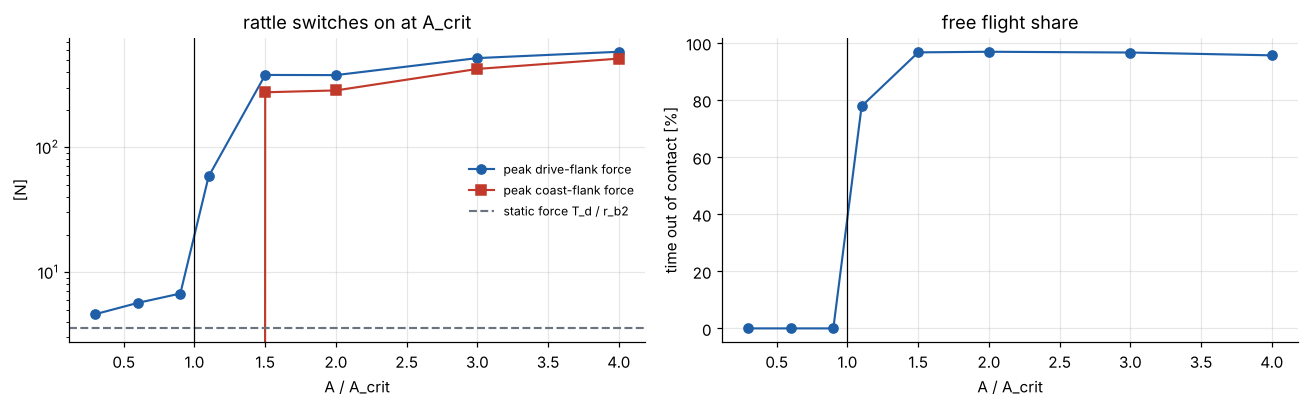

In [7]:
amps = np.r_[0.3, 0.6, 0.9, 1.1, 1.5, 2.0, 3.0, 4.0] * A_crit
res = []
for A in amps:
    r = rattle(A, t_end=0.10, n_out=20000)
    sel = r.t > 0.04
    m_ = r.mesh[0]
    n_coast = np.sum(np.diff((m_["Fr"][sel] > 0).astype(int)) == 1)
    periods = (r.t[sel][-1] - r.t[sel][0]) * we / (2 * np.pi)
    res.append([n_coast / periods, np.max(m_["F"][sel]), np.max(m_["Fr"][sel]), np.mean(m_["F"][sel] == 0)])
res = np.array(res)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(amps / A_crit, res[:, 1], "o-", label="peak drive-flank force")
ax[0].plot(amps / A_crit, res[:, 2], "s-", label="peak coast-flank force")
ax[0].axhline(Td / gp.rb2, color=gd.C["grey"], ls="--", label="static force T_d / r_b2")
ax[0].set_yscale("log"); ax[0].set_xlabel("A / A_crit"); ax[0].set_ylabel("[N]"); ax[0].legend(fontsize=8)
ax[1].plot(amps / A_crit, res[:, 3] * 100, "o-")
ax[1].set_xlabel("A / A_crit"); ax[1].set_ylabel("time out of contact [%]")
for a in ax:
    a.axvline(1, color="k", lw=0.8)
ax[0].set_title("rattle switches on at A_crit"); ax[1].set_title("free flight share")
plt.tight_layout()
print("coast-flank impacts per excitation cycle:", np.round(res[:, 0], 2))

Below $A_\text{crit}$ the teeth stay in contact and the force is a few N. Just above it, the
peak forces jump by **two orders of magnitude**: impacts against a stiff spring.
Remedies follow from the threshold formula: more drag (a friction element on the loose
gear), less inertia $J_2$, less irregularity (a dual-mass flywheel, a different firing order)
or less backlash (a split "anti-backlash" scissor gear).

## 5  Experiment D: the jump phenomenon

Back to the loaded pair under time-varying stiffness (notebook 03). Near resonance the
linear model predicted negative forces. With backlash the teeth **separate** instead. While
separated the mesh is "softer" (zero stiffness), so the effective natural frequency drops.
This is a **softening** nonlinearity, and the resonance curve leans to the left. Sweep the speed
slowly up and then down, carrying the state over from one speed to the next. The two
sweeps follow different branches, with jumps between them.

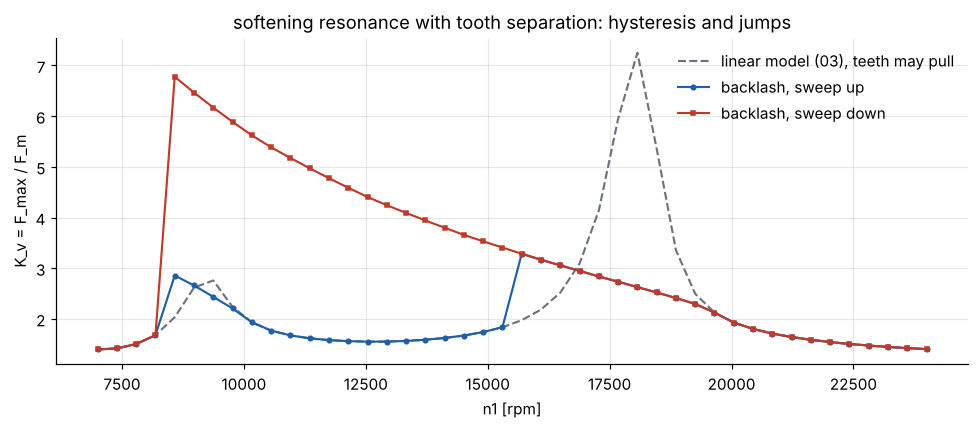

In [8]:
Fm = F0
speeds = np.linspace(7000, 24000, 44)


def sweep(speeds, contact, frac=1.0):
    x0 = None; out = []
    for n in speeds:
        r = gd.simulate_dte(gp, n, frac * Fm, cycles=100, keep=20, x0=x0, contact=contact)
        x0 = list(r["x_end"]); out.append(r["F"].max() / (frac * Fm))
    return np.array(out)


up = sweep(speeds, "backlash")
down = sweep(speeds[::-1], "backlash")[::-1]
lin = sweep(speeds, "linear")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(speeds, lin, color=gd.C["grey"], ls="--", label="linear model (03), teeth may pull")
ax.plot(speeds, up, "o-", ms=3, label="backlash, sweep up")
ax.plot(speeds, down, "s-", ms=3, label="backlash, sweep down")
ax.set_xlabel("n1 [rpm]"); ax.set_ylabel("K_v = F_max / F_m"); ax.legend()
ax.set_title("softening resonance with tooth separation: hysteresis and jumps")
plt.tight_layout()

The up-sweep jumps to the loud branch near 15 500 rpm, well below the linear resonance. The
down-sweep stays on it far down in speed: the bigger the separation, the longer the free
flight and the lower the effective frequency. The loud branch only collapses at about
8 500 rpm, when the teeth swing all the way across and hit the **coast** flank.

Between the jump speeds both a "quiet" and a "loud" steady state exist. Which one you
get depends on history: run-up versus run-down, or a disturbance kicking the gear from one
branch to the other. Separation also *limits* the amplitude compared with the (unphysical)
linear peak.

A subtle point: with only the stiffness excitation and as long as the teeth never reach the
**coast** flank, this curve does not depend on load, because the gap only shifts the
coordinate. Add a manufacturing error at light load (`err=` as in 03, `frac=0.1`) and
**double-sided impacts** appear. That is the noisiest regime.

## 6  Take-aways

* Backlash turns the mesh into two unilateral contacts with a dead zone of width $j_n$.
  Forces can only push.
* Preload-and-release: strain energy becomes flight, then impacts. The undamped impact force
  equals the preload force, and the energy leaves in discrete steps (restitution $e$).
* Free flight makes the frequency **amplitude-dependent**. Separation gives a softening
  resonance with hysteresis and jumps.
* Rattle threshold $A_\text{crit} = i\,T_d/(J_2\omega_e^2)$: above it the force spectrum
  explodes. Fix it with drag, less inertia, less irregularity or anti-backlash gears.

## Exercises

1. In experiment A, plot the time between successive impacts against the impact number and
   fit the geometric decay $e^n$.
2. In experiment C, reduce the backlash to 10 µm. Does the threshold change? Do the impact
   forces? (Threshold no; impact speed and force yes.)
3. Replace the linear contact by a **Hertzian** law $F \propto \text{pen}^{3/2}$ (edit
   `flank_force` in a copy of the mesh class). How does the restitution change with speed?
4. Add a 1 µm profile error at 10 % load to experiment D and find double-sided impacts.
   Plot $\delta(t)$ against the gap band.